# CS-430: Assignment One
## Nik Mrdak

In [1]:
#Importing necessary libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

In [2]:
#Import data from csv
original_data = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Assignment_1/SLCM_Basic_Needs_Class_Practice.csv')

data = original_data.copy()

# Part 1 - Get To Know The Dataset

## 1. Load the CSV file into pandas. What are the dimensions of the dataset?
#### Display the first 5 rows
#### Report the number of rows and columns

In [3]:
data.head(5)

,Housing_Status,Monthly_Housing_Cost,Moves_Last_3_Years,Utility_Disconnection_Risk,Monthly_LGE_Bill,Monthly_Water_Bill,Eviction_Record,Transportation_Need_Score,Has_Car,Bus_Use
0,Renter - past due rent,1200.0,0,Yes,225.0,200.0,No,1,Yes,Never
1,Renter - past due rent,0.0,1,No,217.0,144.0,No,2,Yes,Never
2,Staying with friends or family,800.0,4,No,100.0,100.0,No,5,Yes,Sometimes
3,Homeless,0.0,2,No,0.0,0.0,Yes,0,Yes,Never
4,Homeless,0.0,3,No,0.0,0.0,Yes,3,Yes,Rarely


In [4]:
f'This data contains {data.shape[0]} rows and {data.shape[1]} columns.'

'This data contains 166 rows and 10 columns.'

## 2. What variables are available?
#### Print the column names.
#### For each variable, write one short sentence describing what you think it represents.


In [5]:
print(data.columns)

Index(['Housing_Status', 'Monthly_Housing_Cost', 'Moves_Last_3_Years',
       'Utility_Disconnection_Risk', 'Monthly_LGE_Bill', 'Monthly_Water_Bill',
       'Eviction_Record', 'Transportation_Need_Score', 'Has_Car', 'Bus_Use'],
      dtype='object')


* 'Housing_Status' : Describes living situation and stability
* 'Monthly_Housing_Cost' : Cost of housing for one month
* 'Moves_Last_3_Years' : Number of times person has changed housing in the last three years. Scale.
* 'Utility_Disconnection_Risk' : Yes/No risk of losing utilities.  
* 'Monthly_LGE_Bill' : Price of monthly eletric bill.
* 'Monthly_Water_Bill' : Price of monthly water bill.
* 'Eviction_Record' : Yes/No record of being evicted from home.
* 'Transportation_Need_Score' : Scale of 0-5 need for a means of transportation.
* 'Has_Car' : Yes/No owns a car.
* 'Bus_Use' : Categorical variable measuring frequency of bus usage.


## 3. What data types did pandas assign to the variables?
#### Use info() and/or dtypes.
#### Which columns are numeric?
#### Which columns are categorical/object?
####Does any column have a data type that makes you want to inspect it more closely? Explain.


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 166 entries, 0 to 165
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Housing_Status              166 non-null    object 
 1   Monthly_Housing_Cost        166 non-null    float64
 2   Moves_Last_3_Years          166 non-null    object 
 3   Utility_Disconnection_Risk  166 non-null    object 
 4   Monthly_LGE_Bill            166 non-null    float64
 5   Monthly_Water_Bill          166 non-null    float64
 6   Eviction_Record             166 non-null    object 
 7   Transportation_Need_Score   166 non-null    int64  
 8   Has_Car                     166 non-null    object 
 9   Bus_Use                     166 non-null    object 
dtypes: float64(3), int64(1), object(6)
memory usage: 13.1+ KB


* 'Housing_Status' : Categorical
* 'Monthly_Housing_Cost' : Numerical
* 'Moves_Last_3_Years' : Categorical
* 'Utility_Disconnection_Risk' : Categorical
* 'Monthly_LGE_Bill' : Numerical
* 'Monthly_Water_Bill' : Numerical
* 'Eviction_Record' : Categorical
* 'Transportation_Need_Score' : Numerical
* 'Has_Car' : Categorical
* 'Bus_Use' : Categorical

The variable I am most interested in inspecting more closely is 'Moves_Last_3_Years' because it is a categorical variable, but the values are a scale of integers 0-5.

## 4. What values occur in each categorical variable?
#### Use value_counts() for Housing_Status, Utility_Disconnection_Risk, Eviction_Record, Has_Car,Bus_Use, and Moves_Last_3_Years.
#### Which categories are most common?
#### Do you notice any values that may need clarification or cleaning?

In [7]:
# value_counts() for Housing_Status, Utility_Disconnection_Risk, Eviction_Record, Has_Car,Bus_Use, and Moves_Last_3_Years.
print(data['Housing_Status'].value_counts())
print('~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~')
print(data['Utility_Disconnection_Risk'].value_counts())
print('~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~')
print(data['Eviction_Record'].value_counts())
print('~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~')
print(data['Has_Car'].value_counts())
print('~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~')
print(data['Bus_Use'].value_counts())

Housing_Status
Renter - no rent past due                               68
Renter - past due rent                                  51
Homeless                                                19
Staying at extended stay hotel or short-term housing    15
Staying with friends or family                          12
Own home - mortgage past due                             1
Name: count, dtype: int64
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Utility_Disconnection_Risk
No       116
Yes       40
Maybe     10
Name: count, dtype: int64
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Eviction_Record
No          114
Yes          42
Not sure     10
Name: count, dtype: int64
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Has_Car
Yes    87
No     79
Name: count, dtype: int64
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Bus_Use
Never        66
Often        47
Sometimes    35
Rarely       18
Name: count, dtype: int64


#### Most Common Value
* 'Housing_Status' : 'Renter - no rent past due' [68]
* 'Utility_Disconnection_Risk' : 'No' [116]
* 'Eviction_Record' : 'No' [114]
* 'Has_Car' : 'Yes' [87]
* 'Bus_Use' : 'Never' [66]

The variables I noticed that may need clarification or cleaning are all of the variables outside of yes/no. For example, 'Eviction_Record' has ten 'Not sure' values. Will possibly need imputing or dropping.


# Part 2 – Investigate Data Quality

## 5. Are there missing values or duplicate rows?
#### Calculate the number of missing values in every column.
#### Check for duplicate rows.
#### Report what you find.


In [8]:
data.isnull().sum().sort_values(ascending=False)

,0
Housing_Status,0
Monthly_Housing_Cost,0
Moves_Last_3_Years,0
Utility_Disconnection_Risk,0
Monthly_LGE_Bill,0
Monthly_Water_Bill,0
Eviction_Record,0
Transportation_Need_Score,0
Has_Car,0
Bus_Use,0


In [9]:
data.duplicated().sum()
#data.drop_duplicates(inplace=True)

np.int64(1)

.isnull shows that there are no columns that contain missing values, and .duplicated shows there is only one duplicated row.

## 6. What do the numeric variables look like?
#### Use describe() for Monthly_Housing_Cost, Monthly_LGE_Bill, Monthly_Water_Bill, and Transportation_Need_Score.
#### For each variable, identify its minimum, maximum, and typical values.
#### Which values look unusual or deserve a closer look?


In [10]:
data[['Monthly_Housing_Cost', 'Monthly_LGE_Bill', 'Monthly_Water_Bill', 'Transportation_Need_Score']].describe()

,Monthly_Housing_Cost,Monthly_LGE_Bill,Monthly_Water_Bill,Transportation_Need_Score
count,166.000000,166.000000,166.000000,166.000000
mean,625.209181,420.003320,42.167815,2.433735
std,560.109409,3587.214867,99.524462,1.796918
min,0.000000,0.000000,0.000000,0.000000
25%,0.010000,0.010000,0.000000,1.000000
50%,550.000000,120.000000,0.010000,3.000000
75%,1100.000000,200.000000,60.000000,4.000000
max,2000.000000,46247.000000,1000.000000,5.000000


Numeric variables and their min, max, and typical values.
* 'Monthly_Housing_Cost' : 0, 2000, mean = 625.2
* 'Monthly_LGE_Bill' : 0, 46247, median = 120
* 'Monthly_Water_Bill' : 0, 1000, mean = 42.2
* 'Transportation_Need_Score' : 0, 5, Scale of 0-5

The value that looks unusual is the 'Monthly_LGE_Bill' max value because its an outlier very far from the majority of data points.

## 7. Investigate zero values.
#### Count how many records have Monthly_Housing_Cost = 0.
#### Count how many records have Monthly_LGE_Bill = 0 and Monthly_Water_Bill = 0.
#### Look at Housing_Status for records with Monthly_Housing_Cost = 0.
#### Does a zero always appear to mean “bad data”? Explain what else zero could reasonably mean in this dataset.

In [11]:
print(f'There are {data['Monthly_Housing_Cost'].value_counts()[0]} observations with a monthly housing cost of zero.')

There are 31 observations with a monthly housing cost of zero.


In [12]:
print(f'There are {data['Monthly_LGE_Bill'].value_counts()[0]} observations with a monthly LGE bill of zero.')

There are 36 observations with a monthly LGE bill of zero.


In [13]:
#Housing_Status for records with Monthly_Housing_Cost = 0.
data[data['Monthly_Housing_Cost'] == 0]['Housing_Status'].value_counts()

,count
Housing_Status,
Renter - no rent past due,14
Homeless,13
Staying with friends or family,2
Renter - past due rent,1
Staying at extended stay hotel or short-term housing,1


Zero values do not necessarily indicate 'bad data'. In this context, the majority of zero values for monthly housing costs belong to people who are renters with no rent past due or people who are homeless. This is a logical justification for the majority of these data points.

## 8. Investigate Moves_Last_3_Years.
#### Display all unique values and their counts.
#### Can the values be used directly as numbers?
#### If not, explain how you would clean or recode this variable for future analysis.

In [14]:
data['Moves_Last_3_Years'].unique()

array(['0', '1', '4', '2', '3', 'More than 5', '5'], dtype=object)

These values are categorical and not able to be used as numbers right away. To fix this, I would imput 6 for the 'More than 5' values, and change the variable's data type to an integer. This would enable analysis of this variable.

## 9. Make a cleaned working copy of the dataset.
#### Create a new DataFrame for your cleaned data.
#### Make at least TWO reasonable cleaning/preparation changes based on what you found above.
#### For each change, explain exactly what you changed and why.
#### Run checks afterward to verify that the changes worked.

In [15]:
data_copy = data.copy()

In [16]:
#data_copy.head(3)

In [17]:
#Imput '6' for 'More_than_5' in the 'Moves_Last_3_Years' column.
data_copy['Moves_Last_3_Years'] = data_copy['Moves_Last_3_Years'].apply(lambda x: 6 if x == 'More than 5' else x)

#Change the variable's datatype to integer.
data_copy['Moves_Last_3_Years'] = data_copy['Moves_Last_3_Years'].astype(int)

#Verify
print(data_copy['Moves_Last_3_Years'].dtype)
print(data_copy['Moves_Last_3_Years'].unique())

int64
[0 1 4 2 3 6 5]


I noticed that the 'Moves_Last_3_Years' column contained a string among integers. So that this column can be included in analysis, I replaced 'More than 5' with a six and converted the column's dtype to integer.

In [18]:
#All values 500 or less except two.
#data_copy['Monthly_LGE_Bill'].value_counts().sort_values(ascending = False)

In [19]:
#With a median of 120, need to imput median for all values over 500 for monthly LGE bill.
#data_copy['Monthly_LGE_Bill'] = data_copy['Monthly_LGE_Bill'].apply(lambda x: data_copy['Monthly_LGE_Bill'].median() if x > 500 else x)
data_copy['Monthly_LGE_Bill'] = data_copy['Monthly_LGE_Bill'].apply(lambda x: 120 if x > 500 else x)
#Values less than one, imput zero.
data_copy['Monthly_LGE_Bill'] = data_copy['Monthly_LGE_Bill'].apply(lambda x: 0 if x < 1 else x)

In [20]:
#Value counts of monthly lge bill in descending order
#data_copy['Monthly_LGE_Bill'].value_counts().sort_values(ascending = False)

I identified two outliers in the 'Monthly_LGE_Bill' column with values well exceeding the majority of values. In addition, I identified multiple values less than one. With this, I replaced the two outliers > 500 with the median, and replaced all values < 1 with zero. I chose to implement these specific changes to avoid dropping any observations while removing potential points of data that may skew analytical findings.

# Part 3 – Guided Exploration and Visualization

## 10. What does housing status look like in this dataset?
#### Create a frequency table for Housing_Status.
#### Create an appropriate visualization.
#### Which housing status is most common? What do you notice about the overall distribution?

In [21]:
#Create a frequency table for Housing_Status and show as percents
data_copy['Housing_Status'].value_counts(normalize = True).round(2)

,proportion
Housing_Status,
Renter - no rent past due,0.41
Renter - past due rent,0.31
Homeless,0.11
Staying at extended stay hotel or short-term housing,0.09
Staying with friends or family,0.07
Own home - mortgage past due,0.01


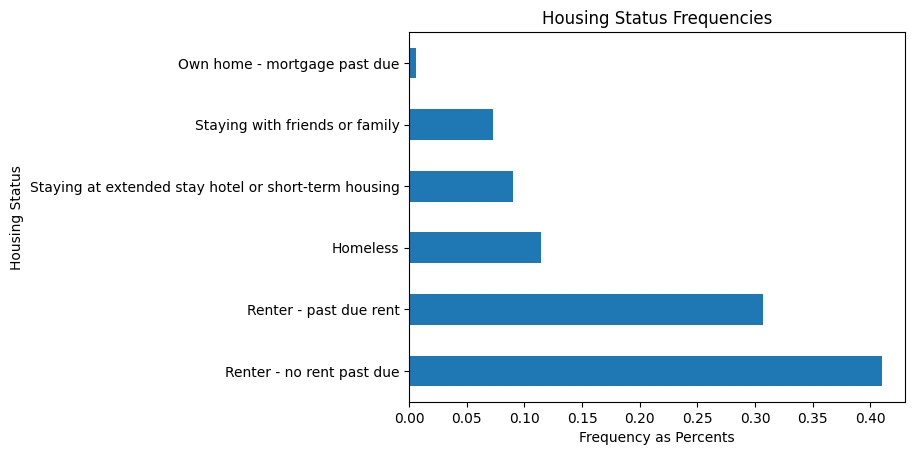

In [22]:
#barh for horizontal bars not vertical
data_copy['Housing_Status'].value_counts(normalize = True).plot(kind = 'barh')

plt.title('Housing Status Frequencies')
plt.xlabel('Frequency as Percents')
plt.ylabel('Housing Status')

plt.show()

The most common housing status is renters with no past due rent. While the other housing statuses have smaller frequencies, together they make up more than half of all entries. This means that more than half of observations are unstable in their housing status.

## 11. How does monthly housing cost vary across housing situations?
#### Compare Monthly_Housing_Cost across Housing_Status.
#### Use a suitable summary and/or visualization.
#### What pattern do you notice?
#### Be careful when interpreting zero housing cost. Explain why.

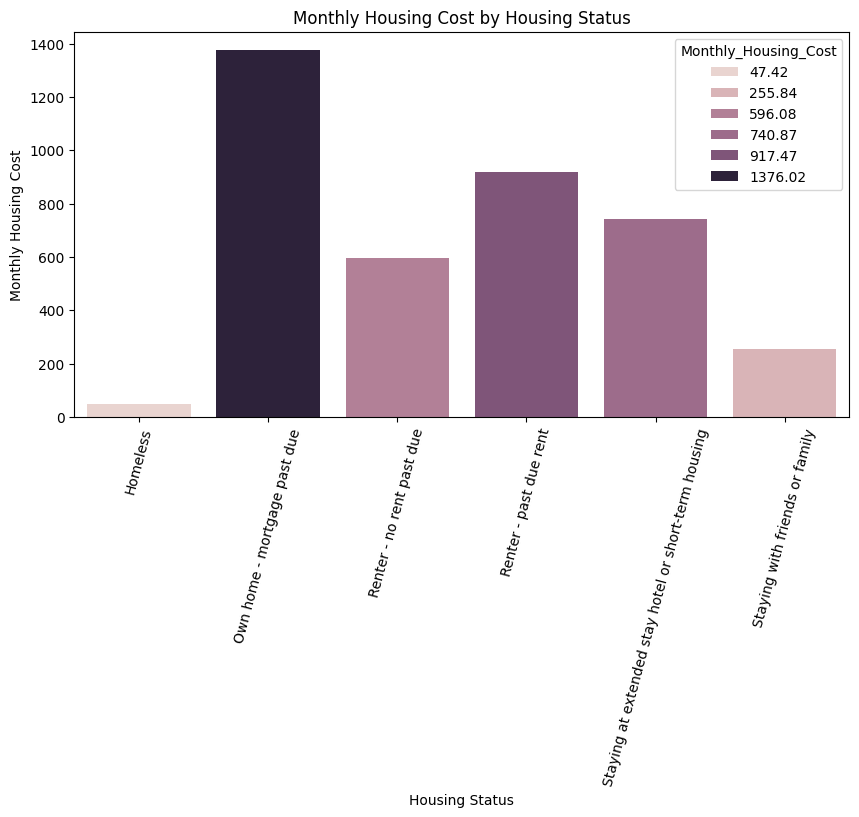

Housing_Status
Homeless                                                  47.42
Own home - mortgage past due                            1376.02
Renter - no rent past due                                596.08
Renter - past due rent                                   917.47
Staying at extended stay hotel or short-term housing     740.87
Staying with friends or family                           255.84
Name: Monthly_Housing_Cost, dtype: float64


In [23]:
#How does monthly housing cost vary across housing status? Compare the two
#with a visual
plt.figure(figsize = (10, 5))
CostStatus = data_copy.groupby('Housing_Status')['Monthly_Housing_Cost'].mean().round(2)

sns.barplot(x = CostStatus.index, y = CostStatus.values, hue = CostStatus)

plt.title('Monthly Housing Cost by Housing Status')
plt.xlabel('Housing Status')
plt.ylabel('Monthly Housing Cost')
plt.xticks(rotation = 75)
plt.show()

print(CostStatus)

The housing status with the hghest monthly housing cost is own home with mortgage past due. This category only has one observation, so it is not generally descriptive. The second highest is renter with past due rent. This makes sense as those struggling to keep up with rent may have higher rent costs or have accrued other expenses related to their lateness. The observations with zero housing costs may misrepresent the true costs. These zero values may be attributed to people living with others, eviction, or subsidised housing cost. A zero value may not turely mean the housing cost for that individual is zero.

## 12. Is utility disconnection risk associated with a different LG&E bill pattern?
#### Compare Monthly_LGE_Bill for people with different Utility_Disconnection_Risk values.
#### Create an appropriate visualization.
#### Describe what you observe. Do not claim that one variable causes the other.

In [24]:
#Compare Monthly_LGE_Bill for people with different Utility_Disconnection_Risk values with the appropriate visualization.
data_copy.groupby('Utility_Disconnection_Risk')['Monthly_LGE_Bill'].median().round(2)

,Monthly_LGE_Bill
Utility_Disconnection_Risk,
Maybe,185.0
No,93.5
Yes,175.0


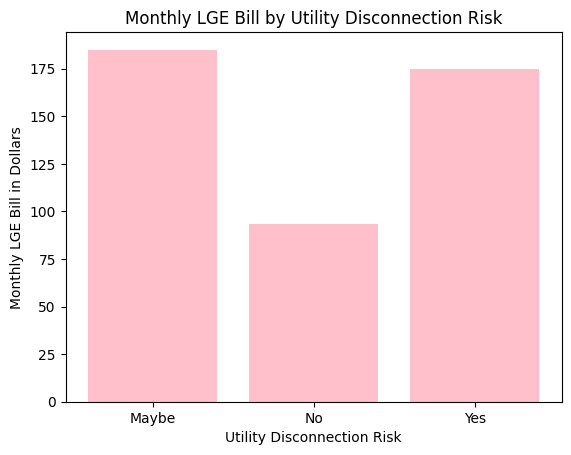

In [25]:
plt.bar(data_copy.groupby('Utility_Disconnection_Risk')['Monthly_LGE_Bill'].median().index, data_copy.groupby(
    'Utility_Disconnection_Risk')['Monthly_LGE_Bill'].median().values, color = 'pink'
)

plt.title('Monthly LGE Bill by Utility Disconnection Risk')
plt.xlabel('Utility Disconnection Risk')
plt.ylabel('Monthly LGE Bill in Dollars')
plt.xticks(rotation = 0)

plt.show()

There is a correlation between people with higher LGE bills and those maybe and certianly at risk of utility disconnection. This may be attributed to factors that would incease one's needs for power like having children.

## 13. What does transportation need look like for people with and without a car?
#### Compare Transportation_Need_Score by Has_Car.
#### Use summary statistics and a visualization.
#### Does car ownership appear related to transportation need in this dataset? Explain using evidence

In [26]:
print(data_copy.groupby('Has_Car')['Transportation_Need_Score'].mean().round(2))
print(data_copy.groupby('Has_Car')['Transportation_Need_Score'].median().round(2))

Has_Car
No     3.27
Yes    1.68
Name: Transportation_Need_Score, dtype: float64
Has_Car
No     4.0
Yes    1.0
Name: Transportation_Need_Score, dtype: float64


/tmp/ipykernel_39409/1294214000.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x = data_copy.groupby('Has_Car')['Transportation_Need_Score'].mean().index, y = data_copy.groupby(


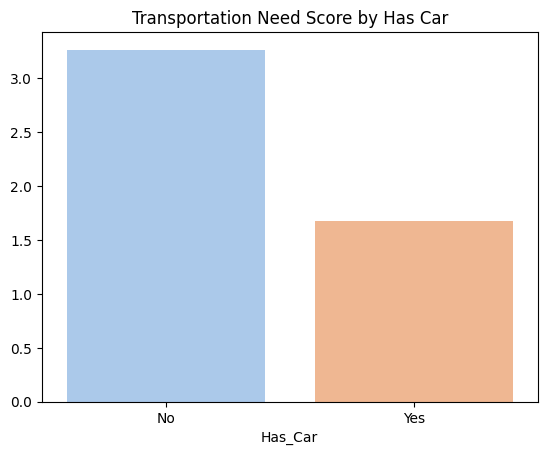

In [27]:
sns.barplot(x = data_copy.groupby('Has_Car')['Transportation_Need_Score'].mean().index, y = data_copy.groupby(
    'Has_Car')['Transportation_Need_Score'].mean().values, palette = 'pastel'
)

plt.title('Transportation Need Score by Has Car')
plt.show()

The need for transportation is evident to be correlated with whether or not one owns a car.

## 14. How is bus use distributed?
#### Create a frequency table and visualization for Bus_Use.
#### What is the most common bus-use category?
#### What additional variable would you compare with Bus_Use if you wanted to understand transportation needs better? Why?


In [28]:
#Create a frequency table and visualization for Bus_Use
data_copy['Bus_Use'].value_counts(normalize = True).round(2)
print(f'The most common bus use type is {data_copy["Bus_Use"].value_counts().idxmax()}')

The most common bus use type is Never


In [29]:
px.histogram(data_copy, x = 'Bus_Use', color = 'Bus_Use')

To better understand transportation needs, I would look at Bus_Use along side Transportation_Need_Score. Looking at these two variables together would enable me to see how frequently those riding the bus are in need of transportation. Finding any pototential correlation between the two would help understand how to help those who are in most need of reliable transportation.

# Part 4 – Your Question
Now that you have worked through the guided exploration, ask ONE question of your own. Your question
must be answerable using variables in this dataset and should investigate something you genuinely noticed
or became curious about.


## 15. What is your question?
#### Write the question clearly.
#### Why did you choose this question? What made you curious about it, and why might it be useful to understand?
#### Which variables will you use to investigate it?


In [30]:
data_copy.columns

Index(['Housing_Status', 'Monthly_Housing_Cost', 'Moves_Last_3_Years',
       'Utility_Disconnection_Risk', 'Monthly_LGE_Bill', 'Monthly_Water_Bill',
       'Eviction_Record', 'Transportation_Need_Score', 'Has_Car', 'Bus_Use'],
      dtype='object')

## 🚗
Question: Is there any correlation between transportation need score and method of transportation?

I believe this question is important to ask as understaning if people's transportation needs are being met is critical in fostering an indavidual's stability. If one cannot get to work, school, grocery store, etc - how can one thrive or survive?

The variables I will utilize to find an answer to this question are Has_Car, Bus_Use, and Transportation_Need_Score.

## 16. What does the data tell you?
#### Use appropriate calculations, grouping, and/or visualization to investigate your question.
#### Show evidence rather than giving only an opinion.
#### Explain what the result suggests in plain language.


In [31]:
#First need to convert Has_Car variables to boolean
data_copy['Has_Car'] = data_copy['Has_Car'].apply(lambda x: True if x == 'Yes' else False)

In [32]:
#Correlation matrix between Has_Car, Bus_Use, and Transportation_Need_Score.
data_copy[['Has_Car', 'Transportation_Need_Score']].corr()

#There is slight negative correlation between car ownership and transportation need.
#Maybe those who own cars have slightly lower transportation needs.

,Has_Car,Transportation_Need_Score
Has_Car,1.000000,-0.442595
Transportation_Need_Score,-0.442595,1.000000


In [33]:
px.histogram(data_copy, x = 'Transportation_Need_Score', color = 'Bus_Use')

#The distribution of those who never use the bus is positively skewed, and those who often ride the bus are more symmetric.
#Those who never ride the bus have lower transportation needs than those who often do.

In [35]:
#Comparing Has_Car and Bus_Use with a visualization
px.histogram(data_copy, x = 'Has_Car', color = 'Bus_Use')

#A majority of people who often use the bus do not own a car. There is a considerable portiton of
#people who do own a car who still ride the bus either sometimes or rarely.
#A small portion of people do not own a car and never ride the bus.

## 17. What is your overall finding?
#### In 3-5 sentences, state the most important finding from your own question.
#### Explain why you think this finding matters.
#### State one limitation: what can you NOT conclude from your analysis?

My findings indicate that transportation need may be associated with both car ownership and bus usage. Those who often ride the bus generally have higher needs for reliable transportation and less likely to own a car; furthermore, those who never use the bus have a stronger tendency to have lower transportation needs. In addition, a significant proportion of car owners still relied on bus transport semi-frequently. These findings suggest that transportation needs are more dependent on bus use than car ownership alone.

While these two metrics together paint a more clear picture of transportation needs together, they do not give us all of the answers. Bus use may reflect one's access to a car, circumstances of car or bus reliability or even other methods of transportation, but without more information I can not validate these assumptions.